# The Burnaev–Vovk Programme: CRR vs. BRR

This notebook empirically checks the claims of Burnaev & Vovk,
*Efficiency of conformalized ridge regression* (COLT 2014), as developed in
**ALRW2 §2.5** (*Efficiency of Conformalized Ridge Regression*).

**The setup.** We want prediction intervals for a linear model
$y_i = w^\top x_i + \xi_i$ with unknown $w$. Two predictors are compared on the
same online stream, using the standard `progressive_val` (test-then-train)
protocol from `online-cp`:

* **CRR** — `ConformalRidgeRegressor`, valid under *exchangeability alone*
  (the hard model).
* **BRR** — a small `BayesianRidgeRegressor` defined below, the Bayes-optimal
  interval under the *soft model* (a Bayesian prior on $w$ and Gaussian noise).
  It is conditionally valid and shortest, but only *if the soft model is right*.

**Theorem 2.7** (ALRW2, eqs. (2.62)–(2.63)): under assumptions (A1)–(A4) —
objects IID with a non-singular second-moment matrix, $w$ independent of the
objects, Gaussian label noise — the CRR and BRR endpoints differ by
$O_p(n^{-1/2})$ and are asymptotically Gaussian. Hence, when the soft model is
correct, CRR is *approximately conditionally valid and efficient*; when it is
wrong, CRR keeps its distribution-free validity at the cost of slightly
wider intervals. The "cheap insurance policy" of conformalizing.

We evaluate with the package's own online metrics — `ErrorRate` (validity),
`IntervalWidth` (sharpness) and `WinklerScore` (a proper score combining both) —
and the package's `plot_coverage` / `plot_set_sizes` utilities.

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from online_cp import (
    ConformalRidgeRegressor,
    ErrorRate,
    IntervalWidth,
    WinklerScore,
    progressive_val,
    plot_coverage,
    plot_set_sizes,
    plot_intervals,
)

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

EPSILON = 0.1   
N_TOTAL = 5000
SEED = 2026

# Bayesian Ridge Regressor

In [57]:
class BayesianRidgeRegressor:
    r"""The soft-model (Bayes-optimal) two-sided interval of Burnaev & Vovk.

    This is the prediction interval the theory (ALRW2 §2.5, eqs. (2.44)–(2.46))
    shows is *asymptotically shortest* and *conditionally valid* under the
    Bayesian soft model: a Gaussian prior $w \sim \mathcal N(0, a^2 I)$ and
    Gaussian label noise $\xi \sim \mathcal N(0, \sigma^2)$.

    With design matrix $X$ (training rows only) and noise covariance
    $\sigma^2 I$, the standard ridge posterior is

    $$\hat w \;=\; (X^\top X + a^2 I)^{-1} X^\top y,
    \qquad
    \Sigma_w \;=\; (X^\top X + a^2 I)^{-1},
    \qquad
    \sigma^2_y \;=\; \sigma^2\big(1 + x^\top \Sigma_w x\big).$$

    The two-sided $\Gamma^\epsilon$ interval is then the normal quantile
    $\hat y \pm z_{1-\epsilon/2}\,\sigma_y$ with $z_{1-\epsilon/2} \approx
    1.96$ at $\epsilon = 0.05$.

    **The design-matrix subtlety that drives the $O(n^{-1/2})$ gap (Thm 2.7).**
    Unlike :class:`~online_cp.ConformalRidgeRegressor` — whose cut-point set is
    built on the *augmented* matrix $[X; x]$ that includes the test row — the
    BRR posterior below is computed on the *training-only* matrix $X$. Burnaev
    & Vovk show that exactly this mismatch between the two design matrices is
    what makes the CRR-BRR endpoints differ by $O_p(n^{-1/2})$ (ALRW2,
    eqs. (2.62)-(2.63)); if both used the same matrix the two would agree to
    first order.

    Note this class is local to the notebook (it is the novel object under
    study, not part of `online-cp`), but it follows the package's
    ``predict``/``learn_one`` contract, so it plugs directly into
    :func:`~online_cp.progressive_val` and the package metrics.
    """

    def __init__(self, a: float = 1.0, sigma: float = 1.0, epsilon: float = 0.05) -> None:
        self.a = float(a)
        self.sigma = float(sigma)
        self.epsilon = float(epsilon)
        self._X: np.ndarray | None = None  # training-only design matrix
        self._y: np.ndarray | None = None

    def learn_one(self, x, y) -> None:
        x = np.asarray(x, dtype=float).reshape(-1)
        if self._X is None:
            self._X = x[None, :]
            self._y = np.array([float(y)])
        else:
            self._X = np.vstack([self._X, x[None, :]])
            self._y = np.concatenate([self._y, [float(y)]])

    def predict(self, x, epsilon: float | None = None, return_update: bool = False):
        from online_cp.prediction_set import ContinuousPredictionSet

        eps = float(self.epsilon if epsilon is None else epsilon)
        if self._X is None or self._X.shape[0] == 0:
            iv = ContinuousPredictionSet((float("-inf"), float("inf")), epsilon=eps)
            return (iv, {}) if return_update else iv

        X = self._X  # <-- training-only design matrix (NOT augmented with x)
        a2 = self.a**2
        s2 = self.sigma**2
        # Ridge posterior: (X^T X + a^2 I)^{-1} X^T y, with posterior cov = (X^T X + a^2 I)^{-1}
        A = X.T @ X + a2 * np.eye(X.shape[1])
        w = np.linalg.solve(A, X.T @ self._y)
        Sig_w = np.linalg.inv(A)

        x = np.asarray(x, dtype=float).reshape(-1)
        y_hat = float(x @ w)
        sig_y = np.sqrt(np.clip(s2 * (1.0 + float(x @ Sig_w @ x)), 1e-12, None))

        z = float(stats.norm.ppf(1.0 - eps / 2.0))
        iv = ContinuousPredictionSet((y_hat - z * sig_y, y_hat + z * sig_y), epsilon=eps)
        # precomputed cache for incremental updates (mirror of the CRR pattern)
        precomputed = {"X": self._X, "y": self._y, "A": A, "Sig_w": Sig_w}
        return (iv, precomputed) if return_update else iv

    # Convenience mirror of the CRR batch-fit API.
    def learn_initial_training_set(self, X, y) -> None:
        for xi, yi in zip(np.asarray(X, float), np.asarray(y, float)):
            self.learn_one(xi, yi)

### Helper functions

In [58]:
def make_metrics():
    """The package's standard regression metric panel (validity + sharpness)."""
    return ErrorRate() + IntervalWidth() + WinklerScore()


def eval_pair(crr, brr, X, y, warm=0, epsilon=EPSILON):
    """Run both predictors on the same stream via `progressive_val`.

    Both are batch-fitted on the first ``warm`` objects and then streamed
    through the package's progressive-validation loop, so the *first*
    prediction each returns is finite — this is what removes the
    "coverage pinned at 1.0" artifact that appears when CRR's warm-up
    (≈ 2/epsilon steps of infinite intervals) is left in place.
    """
    warm = int(warm)
    crr.learn_initial_training_set(X[:warm], y[:warm])
    brr.learn_initial_training_set(X[:warm], y[:warm])

    def stream(model):
        return progressive_val(model, X[warm:], y[warm:], epsilon=epsilon,
                               metric=make_metrics(), progress=True, trace=True)

    return stream(crr), stream(brr)


def generate_soft_model_data(d, n, a, sigma, seed=None):
    """Generate a soft-model stream according to the assumptions
       (A1) The random objects x_i are IID in R^p
       (A2) The second-moment matrix E[x_i x_i^T] esists and is not-singular
       (A3) The random vector w is independent of x_1, x_2,...
       (A4) The labels are generated by y_i = x_i^T w + xi_i, where xi_i is
           IID Gaussian noise with variance sigma^2, independent among themselves,
           of the objects, and of w.
        In particular, the random observations are IID given w.

        This particular choice also satisfies the soft-model assumptions of Burnaev & Vovk (ALRW2, §2.5),
        so their Bayes-optimal two-sided interval is conditionally valid and asymptotically shortest.
    """
    rng = np.random.default_rng(seed)
    X = rng.standard_normal((n, d)) # Gaussian objects (could be any IID distribution with finite second moment
    w = rng.normal(0, sigma**2/a, d) # Gaussian random vector w (could be any distribution independent of the x_i)
    y = X @ w + rng.normal(0, sigma, n) # Labels with Gaussian noise
    return X, y

def generate_IID_data(d, n, seed=None):
    """Generate a stream that is IID, satisfying (A1)-(A4), but not the soft-model assumptions."""
    rng = np.random.default_rng(seed)
    X = rng.standard_normal((n, d))
    w = rng.normal(0, 1, d)
    y = X @ w + rng.normal(0, 1, n)
    return X, y

# Scenario 1 - the soft model holds (Gaussian objects + Gaussian noise)

This is the exact regime of assumptions (A1)–(A4): IID standard-normal
objects, a linear model with fixed $w$, Gaussian label noise, and a Bayesian
prior on $w$ that matches the truth. Here Burnaev–Vovk's Theorem 2.7 predicts
that CRR and BRR produce *almost the same* intervals — the CRR–BRR endpoint
gap is $O_p(n^{-1/2})$ — and that CRR is *approximately conditionally valid*
and *efficient*, behaving like BRR but carrying only exchangeability as its
validity guarantee.

We use $d = 10$, $\sigma = 1$.

In [59]:
d, sigma, a = 10, 0.25, 2.0
X, y = generate_soft_model_data(d, N_TOTAL, a, sigma, seed=SEED)

crr = ConformalRidgeRegressor(a=a, epsilon=EPSILON)
brr = BayesianRidgeRegressor(a=a, sigma=sigma, epsilon=EPSILON)

warm = 20 # > ceil(2/eps) = 20, so CRR is finite from step 1
crr_m, brr_m = eval_pair(crr, brr, X, y, warm=warm)

print("CRR:", crr_m.get())
print("BRR:", brr_m.get())

  0%|          | 0/4980 [00:00<?, ?it/s]

  0%|          | 0/4980 [00:00<?, ?it/s]

CRR: {'ErrorRate': 0.10120481927710843, 'IntervalWidth': 0.8374220243705223, 'WinklerScore': np.float64(1.0513588411606412)}
BRR: {'ErrorRate': 0.10140562248995984, 'IntervalWidth': 0.8270043819172505, 'WinklerScore': np.float64(1.0479509891947212)}


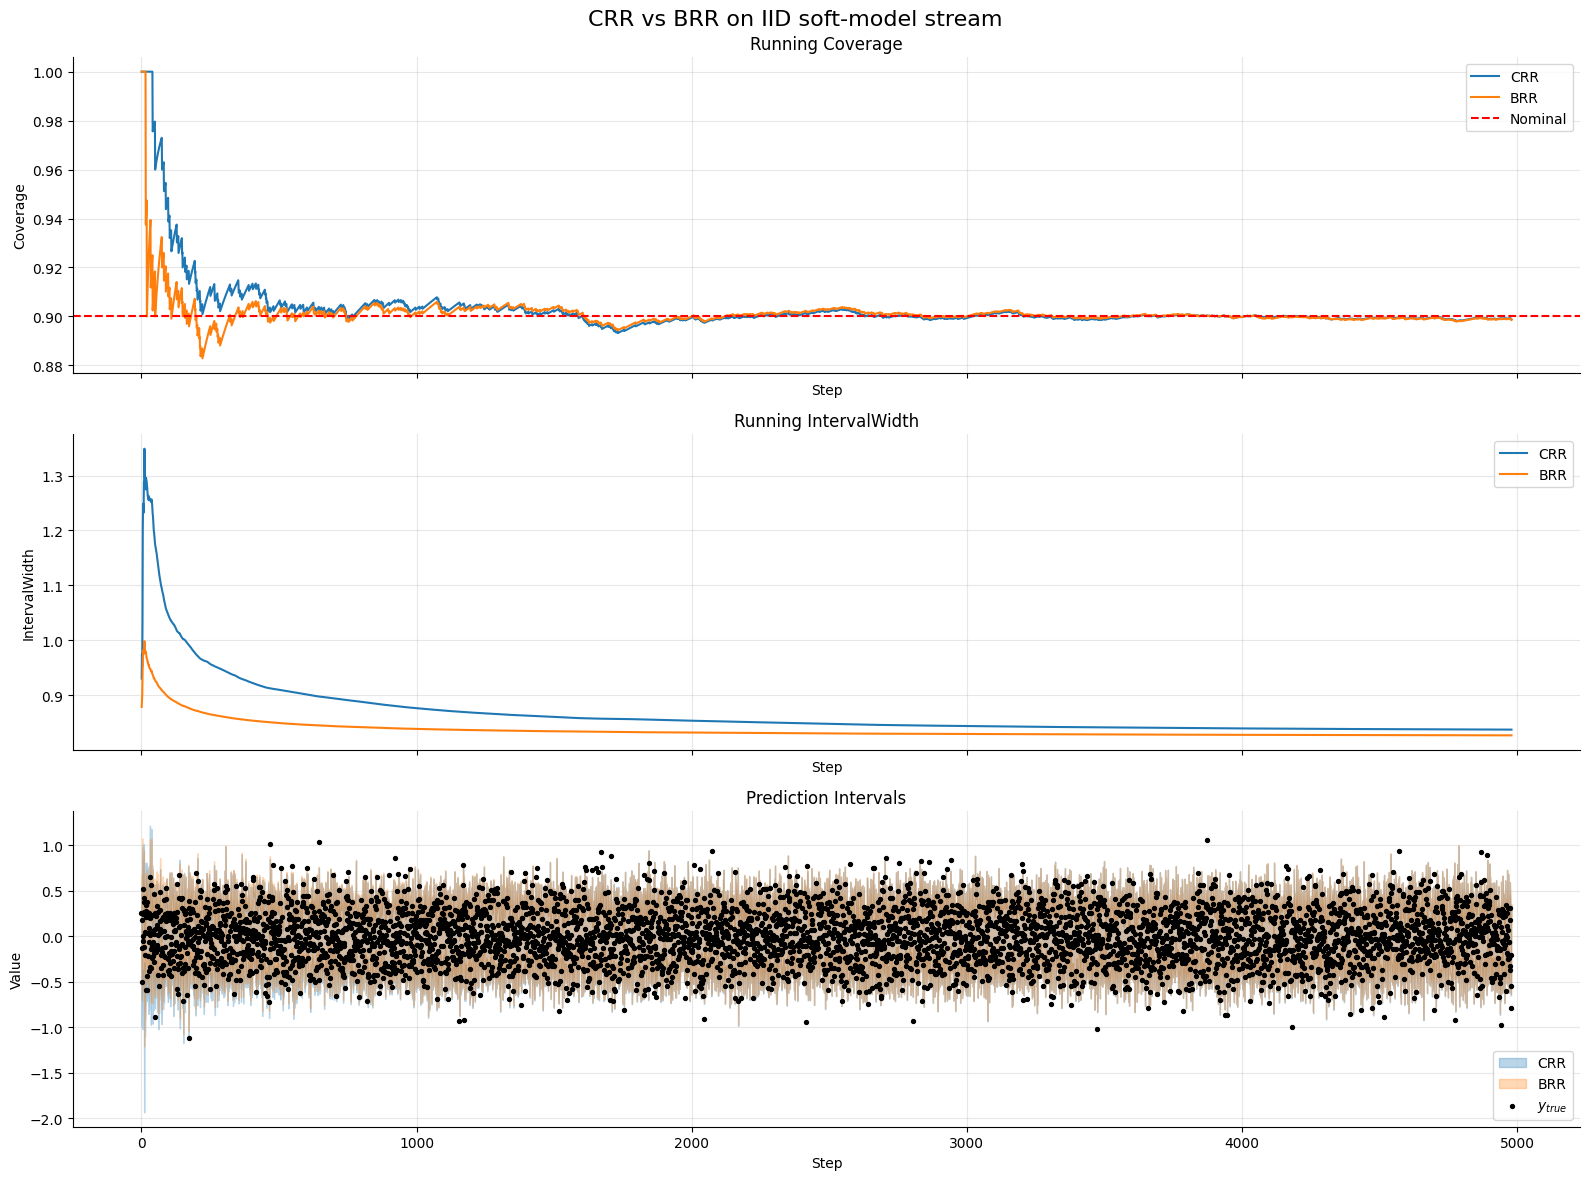

In [60]:
fig, axs = plt.subplots(nrows=3, figsize=(16, 12), sharex=True)
plot_coverage(crr_m, label="CRR", ax=axs[0])
plot_coverage(brr_m, label="BRR", ax=axs[0])
axs[0].axhline(1 - EPSILON, color="red", linestyle="--", label="Nominal")
axs[0].legend()
plot_set_sizes(crr_m, label="CRR", ax=axs[1])
plot_set_sizes(brr_m, label="BRR", ax=axs[1])
plot_intervals(crr_m,  ax=axs[2], interval_kwargs={"color": "C0"}, label="CRR", show_points=False)
plot_intervals(brr_m,  ax=axs[2], interval_kwargs={"color": "C1"}, label="BRR")
fig.suptitle("CRR vs BRR on IID soft-model stream", fontsize=16)
fig.tight_layout()

# Scenario 2 - The soft model is broken

In [61]:
X, y = generate_IID_data(d, N_TOTAL, seed=SEED)

crr = ConformalRidgeRegressor(a=a, epsilon=EPSILON)
brr = BayesianRidgeRegressor(a=a, sigma=sigma, epsilon=EPSILON)

crr_m, brr_m = eval_pair(crr, brr, X, y, warm=warm)

print("CRR:", crr_m.get())
print("BRR:", brr_m.get())

  0%|          | 0/4980 [00:00<?, ?it/s]

  0%|          | 0/4980 [00:00<?, ?it/s]

CRR: {'ErrorRate': 0.10060240963855421, 'IntervalWidth': 3.3513598957916133, 'WinklerScore': np.float64(4.205259958761592)}
BRR: {'ErrorRate': 0.6767068273092369, 'IntervalWidth': 0.8270043819172507, 'WinklerScore': np.float64(9.893077783022012)}


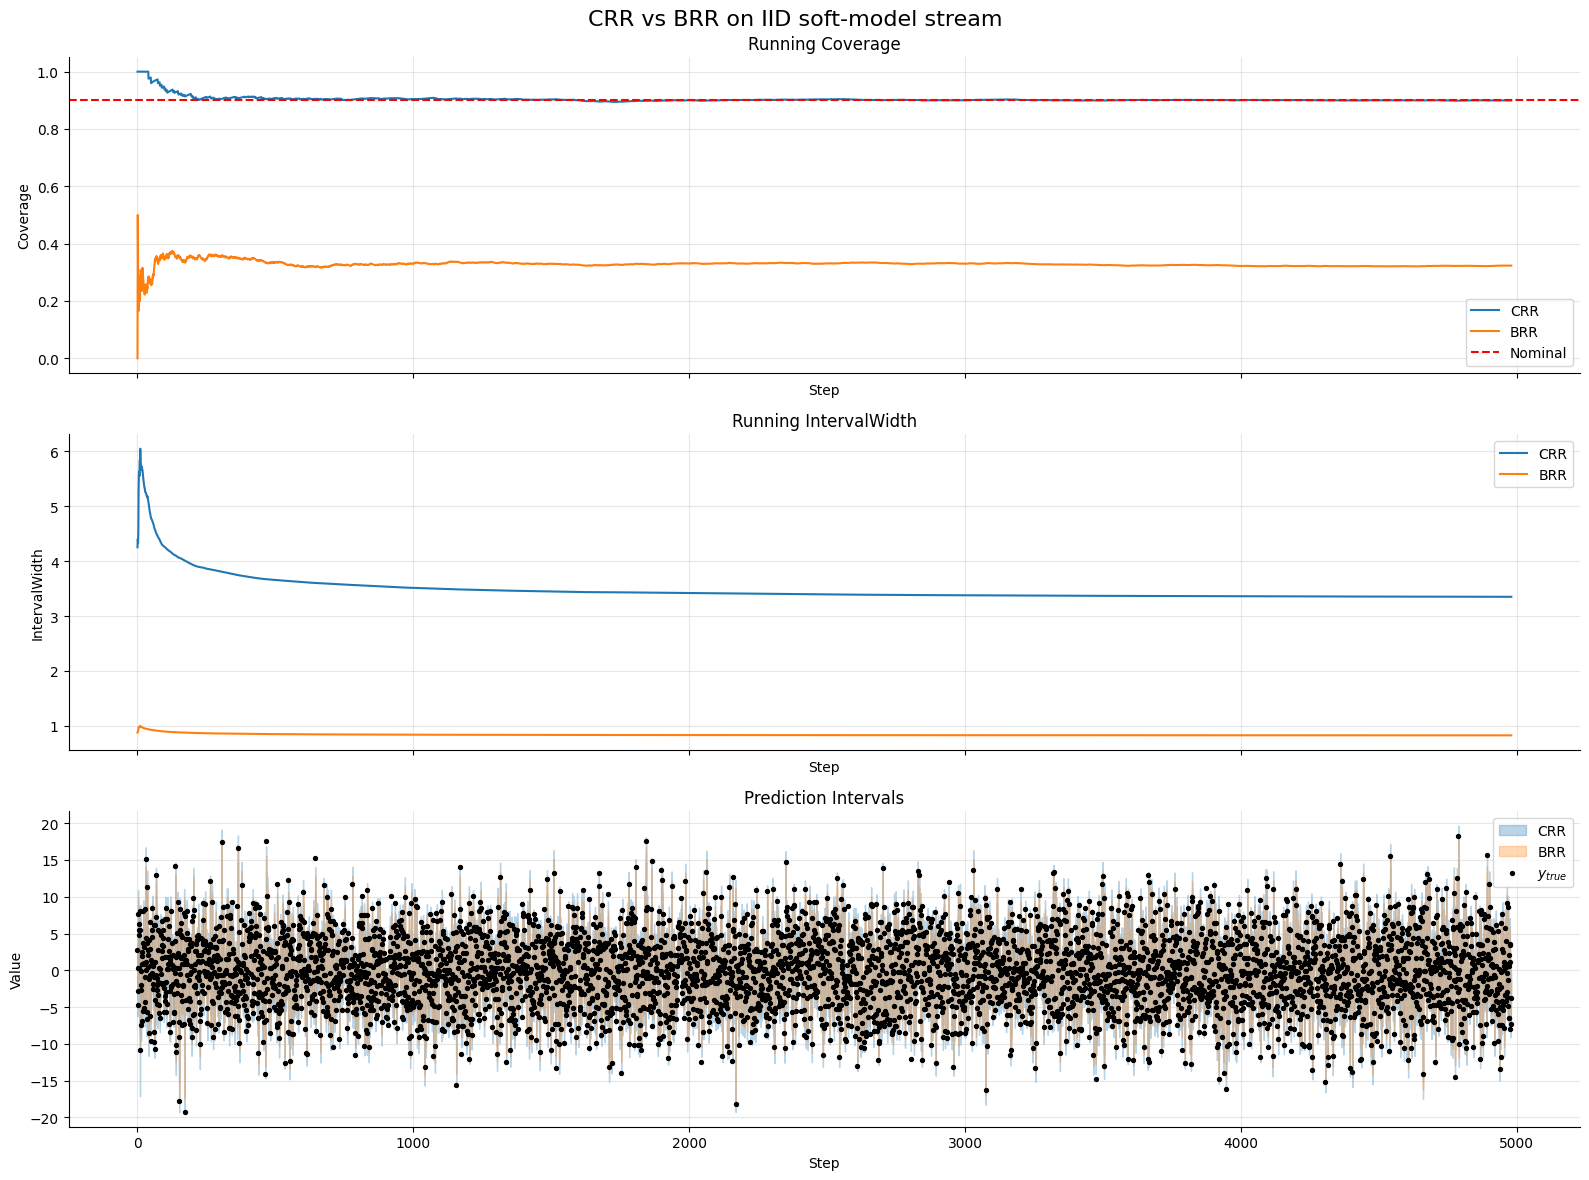

In [62]:
fig, axs = plt.subplots(nrows=3, figsize=(16, 12), sharex=True)
plot_coverage(crr_m, label="CRR", ax=axs[0])
plot_coverage(brr_m, label="BRR", ax=axs[0])
axs[0].axhline(1 - EPSILON, color="red", linestyle="--", label="Nominal")
axs[0].legend()
plot_set_sizes(crr_m, label="CRR", ax=axs[1])
plot_set_sizes(brr_m, label="BRR", ax=axs[1])
plot_intervals(crr_m,  ax=axs[2], interval_kwargs={"color": "C0"}, label="CRR", show_points=False)
plot_intervals(brr_m,  ax=axs[2], interval_kwargs={"color": "C1"}, label="BRR")
fig.suptitle("CRR vs BRR on IID soft-model stream", fontsize=16)
fig.tight_layout()